# Task 3 – Classification of Gear_Type and Options
We predict two categorical features chosen in the EDA:
- **Gear_Type**: Automatic / Manual — binary and **imbalanced** (86% / 14%)
- **Options**: Standard / Semi Full / Full — three fairly balanced classes

For each target we train **Logistic Regression, Decision Tree, Random Forest, SVM and MLP** with grid search,
and evaluate them with the confusion matrix, accuracy, precision, recall and F1.

⏱ About 5 minutes in total.

In [1]:
import sys, json, time, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

from common import (load_raw, clean_rows, make_preprocessor, NUMERIC, CATEGORICAL, MIN_PLAUSIBLE_PRICE,
                    RANDOM_STATE, TEST_SIZE, FIG_DIR, RES_DIR, MODEL_DIR)

sns.set_theme(style="whitegrid")
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Data
**Price as an input:** price helps (Full-option cars cost more), but a third of the ads have no price. We set
unpriced (0) and instalment (< 5,000) prices to missing; the imputer fills them and adds a 0/1
"price was missing" column, so we keep all rows.

In [2]:
base = clean_rows(load_raw())
base.loc[base.Price < MIN_PLAUSIBLE_PRICE, "Price"] = np.nan
print(base.shape)
print(base.Gear_Type.value_counts(normalize=True).round(3).to_dict())
print(base.Options.value_counts(normalize=True).round(3).to_dict())

(8179, 13)
{'Automatic': 0.864, 'Manual': 0.136}
{'Full': 0.398, 'Standard': 0.325, 'Semi Full': 0.277}


## 2. Models, grids and metrics
**Imbalance handling:** for Logistic Regression, Decision Tree, Random Forest and SVM the grid search tries
`class_weight = None` and `"balanced"` (weights inversely proportional to class frequency). MLP has no
`class_weight`, so we pass **balanced sample weights** to `fit()`.

We choose models by **macro-F1**, which treats both classes equally — accuracy alone would reward always
predicting "Automatic".

In [3]:
def models_and_grids():
    return {
        "Logistic Regression": (LogisticRegression(max_iter=3000), {
            "model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}),
        "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {
            "model__max_depth": [5, 10, 20, None], "model__min_samples_leaf": [1, 5, 10],
            "model__class_weight": [None, "balanced"]}),
        "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), {
            "model__max_depth": [20, None], "model__min_samples_leaf": [1, 3],
            "model__class_weight": [None, "balanced"]}),
        "SVM": (SVC(kernel="rbf"), {
            "model__C": [0.3, 1, 10], "model__gamma": ["scale", 0.01],
            "model__class_weight": [None, "balanced"]}),
        "MLP": (MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE), {
            "model__hidden_layer_sizes": [(64,), (128, 64)], "model__alpha": [1e-4, 1e-3, 1e-2]}),
    }

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro"),
            "f1_weighted": f1_score(y_true, y_pred, average="weighted")}

In [4]:
def run_target(target, labels, fig_id):
    df = base.dropna(subset=[target]).reset_index(drop=True)          # the target must be known
    cat_in = [c for c in CATEGORICAL if c != target]
    num_in = NUMERIC + ["Price"]
    features = num_in + cat_in
    X, y = df[features], df[target]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
    print(f"{target}: train {X_train.shape}, test {X_test.shape}")
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    rows, fitted, preds = [], {}, {}
    dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    rows.append({"model": "Baseline (majority)", "cv_f1_macro": np.nan, "best_params": "-",
                 **scores(y_test, dummy.predict(X_test))})

    for name, (est, grid) in models_and_grids().items():
        pipe = Pipeline([("prep", make_preprocessor(num_in, cat_in, add_indicator=True)), ("model", est)])
        fit_params = {"model__sample_weight": compute_sample_weight("balanced", y_train)} if name == "MLP" else {}
        t0 = time.time()
        gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
        gs.fit(X_train, y_train, **fit_params)
        fitted[name], preds[name] = gs.best_estimator_, gs.best_estimator_.predict(X_test)
        params = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
        rows.append({"model": name, "cv_f1_macro": gs.best_score_, "best_params": params,
                     **scores(y_test, preds[name])})
        print(f"  {name:20s} {time.time() - t0:4.0f}s  {params}")

    res = pd.DataFrame(rows)
    res.to_csv(RES_DIR / f"classification_{target}_results.csv", index=False)

    # confusion matrices
    fig, axes = plt.subplots(1, 5, figsize=(24, 4.6))
    for a, (name, p) in zip(axes, preds.items()):
        cm = confusion_matrix(y_test, p, labels=labels)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=labels, yticklabels=labels)
        a.set_title(f"{name}\nF1-macro={f1_score(y_test, p, average='macro'):.3f}")
        a.set_xlabel("Predicted"); a.set_ylabel("Actual")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"2{fig_id}_confusion_{target}.png", dpi=130); plt.show()

    # best model by CV macro-F1
    best_name = res.dropna(subset=["cv_f1_macro"]).sort_values("cv_f1_macro", ascending=False).iloc[0]["model"]
    joblib.dump(fitted[best_name], MODEL_DIR / f"best_classifier_{target.lower()}.joblib", compress=3)
    print(f"\nBest model for {target}: {best_name}")
    print(classification_report(y_test, preds[best_name], labels=labels, digits=3))

    info = {"model": best_name, "features": features, "classes": labels,
            "test_metrics": {k: float(v) for k, v in scores(y_test, preds[best_name]).items()}}
    err = X_test.assign(actual=y_test.values, predicted=preds[best_name])
    return res, info, err, X_train

summary = {}

## 3. Target 1 – Gear_Type

Gear_Type: train (6484, 11), test (1621, 11)
  Logistic Regression    26s  {'C': 10, 'class_weight': None}
  Decision Tree           8s  {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 10}
  Random Forest          33s  {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1}
  SVM                    40s  {'C': 10, 'class_weight': None, 'gamma': 'scale'}
  MLP                    14s  {'alpha': 0.001, 'hidden_layer_sizes': (64,)}


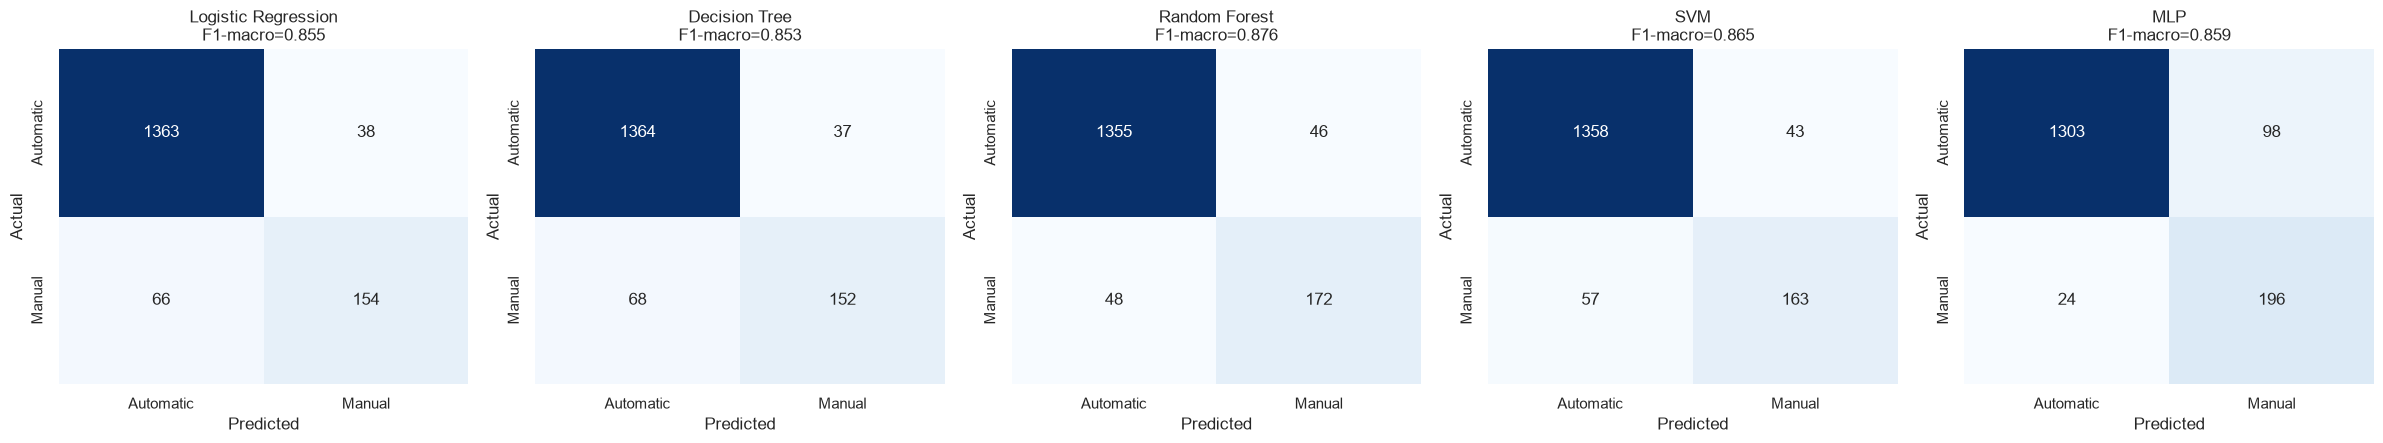


Best model for Gear_Type: Random Forest
              precision    recall  f1-score   support

   Automatic      0.966     0.967     0.966      1401
      Manual      0.789     0.782     0.785       220

    accuracy                          0.942      1621
   macro avg      0.877     0.874     0.876      1621
weighted avg      0.942     0.942     0.942      1621



,model,cv_f1_macro,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,f1_weighted
0,Baseline (majority),NaN,0.864,0.500,0.432,0.500,0.464,0.801
1,Logistic Regression,0.869,0.936,0.836,0.878,0.836,0.855,0.934
2,Decision Tree,0.851,0.935,0.832,0.878,0.832,0.853,0.933
3,Random Forest,0.889,0.942,0.874,0.877,0.874,0.876,0.942
4,SVM,0.867,0.938,0.855,0.875,0.855,0.865,0.937
5,MLP,0.852,0.925,0.910,0.824,0.910,0.859,0.929


In [5]:
res_gear, summary["Gear_Type"], err_gear, Xtr_gear = run_target("Gear_Type", ["Automatic", "Manual"], 0)
res_gear.drop(columns="best_params").round(3)

Always guessing "Automatic" already gives 86% accuracy but a macro-F1 of only 0.46 — that is why we use macro-F1.
The best model must find the minority **Manual** class, not just score high accuracy.

## 4. Target 2 – Options

Options: train (6456, 11), test (1614, 11)
  Logistic Regression     5s  {'C': 0.1, 'class_weight': 'balanced'}
  Decision Tree           7s  {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5}
  Random Forest          39s  {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 1}
  SVM                   136s  {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale'}
  MLP                    18s  {'alpha': 0.0001, 'hidden_layer_sizes': (128, 64)}


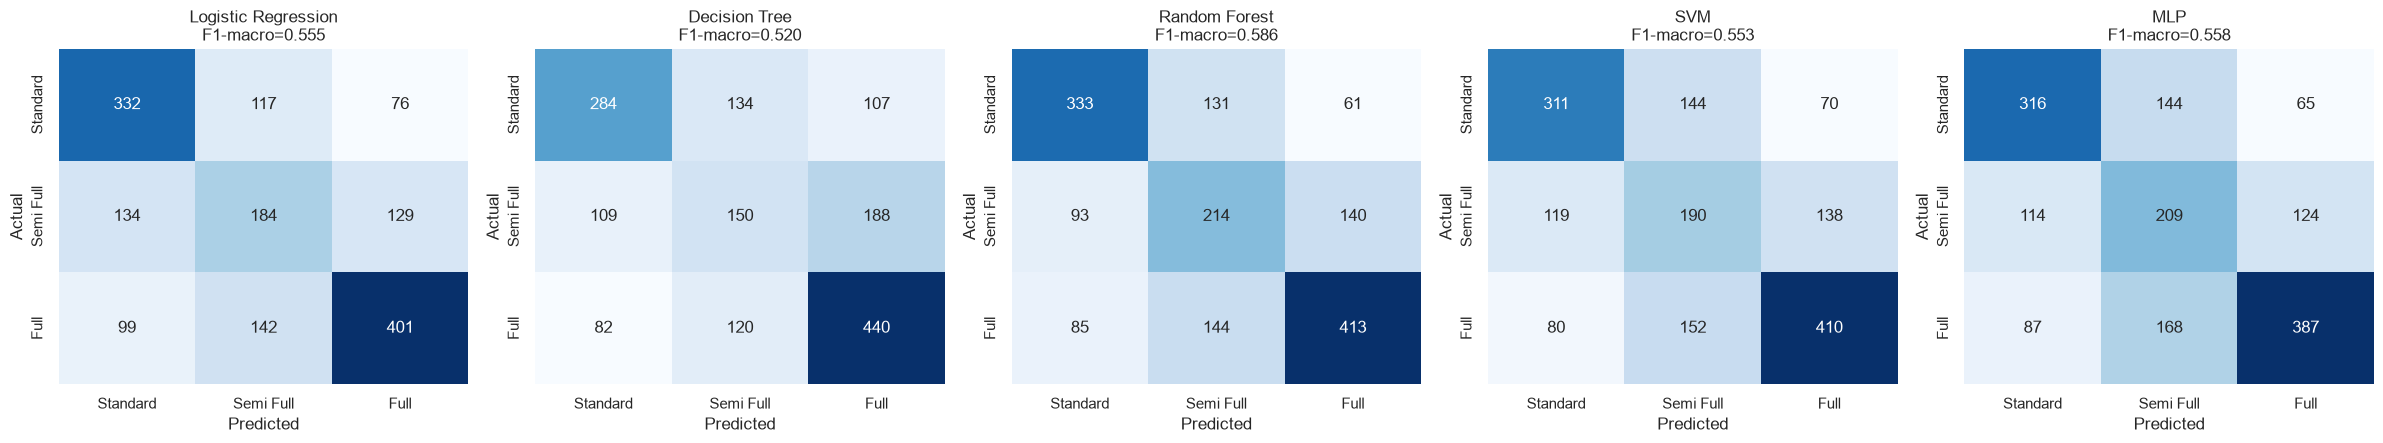


Best model for Options: Random Forest
              precision    recall  f1-score   support

    Standard      0.652     0.634     0.643       525
   Semi Full      0.438     0.479     0.457       447
        Full      0.673     0.643     0.658       642

    accuracy                          0.595      1614
   macro avg      0.587     0.585     0.586      1614
weighted avg      0.601     0.595     0.597      1614



,model,cv_f1_macro,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,f1_weighted
0,Baseline (majority),NaN,0.398,0.333,0.133,0.333,0.190,0.226
1,Logistic Regression,0.552,0.568,0.556,0.555,0.556,0.555,0.568
2,Decision Tree,0.499,0.542,0.521,0.523,0.521,0.520,0.537
3,Random Forest,0.570,0.595,0.585,0.587,0.585,0.586,0.597
4,SVM,0.560,0.564,0.552,0.555,0.552,0.553,0.567
5,MLP,0.554,0.565,0.557,0.561,0.557,0.558,0.570


In [6]:
res_opt, summary["Options"], err_opt, Xtr_opt = run_target("Options", ["Standard", "Semi Full", "Full"], 1)
res_opt.drop(columns="best_params").round(3)

All five models land close to each other (≈0.52–0.59 macro-F1). When very different algorithms reach the
same ceiling, the limit is in the **data**: the same model and year is sold in all three trims and no feature
is strongly associated with Options (EDA: best 0.40).

In [7]:
json.dump(summary, open(MODEL_DIR / "best_classifiers.json", "w"), indent=2)
pd.DataFrame({t: s["test_metrics"] for t, s in summary.items()}).round(3)

,Gear_Type,Options
accuracy,0.942,0.595
balanced_acc,0.874,0.585
precision_macro,0.877,0.587
recall_macro,0.874,0.585
f1_macro,0.876,0.586
f1_weighted,0.942,0.597


## 5. Error analysis

In [8]:
for target, err, X_train in [("Gear_Type", err_gear, Xtr_gear), ("Options", err_opt, Xtr_opt)]:
    wrong = err[err.actual != err.predicted]
    rare = err.Type.map(X_train.Type.value_counts()).fillna(0) < 10
    correct = err.actual == err.predicted
    print(f"===== {target}: {len(wrong)} errors of {len(err)}")
    print(f"Accuracy on rare car models (<10 in train): {correct[rare].mean():.3f}  vs common: {correct[~rare].mean():.3f}")
    print("Most frequent mistakes (actual -> predicted):")
    print(wrong.groupby(["actual", "predicted"]).size().sort_values(ascending=False).head(4).to_string())
    print("Car models with most mistakes:", wrong.Type.value_counts().head(6).to_dict(), "\n")

===== Gear_Type: 94 errors of 1621
Accuracy on rare car models (<10 in train): 0.901  vs common: 0.948
Most frequent mistakes (actual -> predicted):
actual     predicted
Manual     Automatic    48
Automatic  Manual       46
Car models with most mistakes: {'Land Cruiser': 10, 'Hilux': 10, 'Camry': 8, 'Corolla': 4, 'Previa': 3, 'Navara': 3} 

===== Options: 654 errors of 1614
Accuracy on rare car models (<10 in train): 0.583  vs common: 0.597
Most frequent mistakes (actual -> predicted):
actual     predicted
Full       Semi Full    144
Semi Full  Full         140
Standard   Semi Full    131
Semi Full  Standard      93
Car models with most mistakes: {'Camry': 35, 'Yukon': 25, 'Hilux': 22, 'Tahoe': 21, 'Land Cruiser': 21, 'Sonata': 18} 



**Findings**
- **Gear_Type:** errors are on models sold with both gearboxes (Land Cruiser, Hilux, Camry) — nothing in the ad
  tells the two versions apart. Rare models are harder.
- **Options:** most errors involve the middle class *Semi Full*; Standard ↔ Full confusions are much rarer.
  "Semi Full" is probably used inconsistently by sellers.